Import

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
import socket
import time
from datetime import datetime
from pathlib import Path

if socket.gethostname() == "ph-photonbec5":
    sys.path.append(r"D:/Control/PythonPackages/")

import Components as comp

laser = comp.Toptica_Laser()

# Power Meter A only
powermeter = comp.Thor_PowerMeter(
    power_meter_usb_name='USB0::0x1313::0x8078::P0034379::INSTR',
    num_power_readings=15,
    bs_factor=1,
    wavelength=950
)

OUTPUT_DIR = Path(r"D:\Data\2026\202610\20261019")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Data will be saved to:", OUTPUT_DIR.resolve())

print("Hardware initialised: Toptica + Power Meter A")


Data will be saved to: D:\Data\2026\202610\20261019
Hardware initialised: Toptica + Power Meter A


Uniform sampling parameters

In [2]:

MAX_ALLOWED = 0.060  # W, user-reported safety limit
SCAN_STOP = 0.050  # W
NUM_POINTS = 31

SETTLE_SECONDS = 1.0
REPEATS = 3

uniform_settings = np.linspace(
    0.000, SCAN_STOP, NUM_POINTS
)

assert 0 <= uniform_settings.min()
assert uniform_settings.max() <= MAX_ALLOWED
assert REPEATS >= 1
assert SETTLE_SECONDS >= 0

print("Uniform sampling")
print("Number of points:", len(uniform_settings))
print("Laser settings (mW):", uniform_settings * 1000)


Uniform sampling
Number of points: 31
Laser settings (mW): [ 0.          1.66666667  3.33333333  5.          6.66666667  8.33333333
 10.         11.66666667 13.33333333 15.         16.66666667 18.33333333
 20.         21.66666667 23.33333333 25.         26.66666667 28.33333333
 30.         31.66666667 33.33333333 35.         36.66666667 38.33333333
 40.         41.66666667 43.33333333 45.         46.66666667 48.33333333
 50.        ]


Uniform measurement

In [3]:

# Confirm laser units, approved scan and optical alignment first.
confirm = input("Type YES to begin UNIFORM hardware scan: ")
if confirm != "YES":
    raise RuntimeError("Scan cancelled")

uniform_p = []
uniform_y = []
uniform_err = []

uniform_file = OUTPUT_DIR / (
        "uniform_" + datetime.now().strftime("%Y%m%d_%H%M%S") + ".csv"
)

try:
    with open(uniform_file, "w", newline="") as f:
        writer = __import__("csv").writer(f)
        writer.writerow([
            "Laser_setting_W",
            "Output_power_W",
            "Std_power_W",
            "Timestamp"
        ])

        for x in uniform_settings:
            if not (0 <= x <= MAX_ALLOWED):
                raise ValueError("Setting outside approved range")

            laser.set(float(x))
            time.sleep(SETTLE_SECONDS)

            readings = np.array([
                powermeter.take_power_reading()
                for _ in range(REPEATS)
            ], dtype=float)

            mean = float(np.mean(readings))
            std = float(np.std(readings, ddof=1)) if REPEATS > 1 else 0.0

            uniform_p.append(float(x))
            uniform_y.append(mean)
            uniform_err.append(std)

            writer.writerow([
                float(x), mean, std,
                datetime.now().isoformat()
            ])
            f.flush()

            print(
                f"{x * 1000:6.2f} mW | "
                f"Output: {mean * 1000:.6f} mW"
            )

finally:
    print("Scan ended or interrupted.")
    print("Follow lab procedure for laser state.")

uniform_p = np.asarray(uniform_p)
uniform_y = np.asarray(uniform_y)
uniform_err = np.asarray(uniform_err)

print("Uniform data saved:", uniform_file)


  0.00 mW | Output: 0.000009 mW
  1.67 mW | Output: 0.000010 mW
  3.33 mW | Output: 0.000011 mW
  5.00 mW | Output: 0.000012 mW
  6.67 mW | Output: 0.000012 mW
  8.33 mW | Output: 0.000013 mW
 10.00 mW | Output: 0.000013 mW
 11.67 mW | Output: 0.000014 mW
 13.33 mW | Output: 0.000015 mW
 15.00 mW | Output: 0.000016 mW
 16.67 mW | Output: 0.000201 mW
 18.33 mW | Output: 0.002944 mW
 20.00 mW | Output: 0.004984 mW
 21.67 mW | Output: 0.006855 mW
 23.33 mW | Output: 0.008760 mW
 25.00 mW | Output: 0.012710 mW
 26.67 mW | Output: 0.020219 mW
 28.33 mW | Output: 0.029133 mW
 30.00 mW | Output: 0.035201 mW
 31.67 mW | Output: 0.038895 mW
 33.33 mW | Output: 0.043895 mW
 35.00 mW | Output: 0.054219 mW
 36.67 mW | Output: 0.086534 mW
 38.33 mW | Output: 0.089272 mW
 40.00 mW | Output: 0.083406 mW
 41.67 mW | Output: 0.083358 mW
 43.33 mW | Output: 0.083620 mW
 45.00 mW | Output: 0.089223 mW
 46.67 mW | Output: 0.056086 mW
 48.33 mW | Output: 0.059236 mW
 50.00 mW | Output: 0.044299 mW
Scan end

Manual non-uniform sampling parameters

In [4]:

# Low region: 0–15 mW, 3 mW steps
region1 = np.arange(0.000, 0.015, 0.003)

# Transition region: 15–30 mW, 0.5 mW steps
region2 = np.arange(0.015, 0.030, 0.0005)

# High region: 30–50 mW, 2 mW steps
region3 = np.arange(0.030, 0.0501, 0.002)

manual_settings = np.unique(
    np.round(
        np.concatenate([region1, region2, region3]),
        7
    )
)

assert manual_settings.min() >= 0
assert manual_settings.max() <= MAX_ALLOWED

print("Manual non-uniform sampling")
print("Number of points:", len(manual_settings))
print("Laser settings (mW):", manual_settings * 1000)


Manual non-uniform sampling
Number of points: 46
Laser settings (mW): [ 0.   3.   6.   9.  12.  15.  15.5 16.  16.5 17.  17.5 18.  18.5 19.
 19.5 20.  20.5 21.  21.5 22.  22.5 23.  23.5 24.  24.5 25.  25.5 26.
 26.5 27.  27.5 28.  28.5 29.  29.5 30.  32.  34.  36.  38.  40.  42.
 44.  46.  48.  50. ]


Manual Measurement

In [5]:

confirm = input("Type YES to begin MANUAL hardware scan: ")
if confirm != "YES":
    raise RuntimeError("Scan cancelled")

manual_p = []
manual_y = []
manual_err = []

manual_file = OUTPUT_DIR / (
        "manual_" + datetime.now().strftime("%Y%m%d_%H%M%S") + ".csv"
)

try:
    with open(manual_file, "w", newline="") as f:
        writer = __import__("csv").writer(f)
        writer.writerow([
            "Laser_setting_W",
            "Output_power_W",
            "Std_power_W",
            "Timestamp"
        ])

        for x in manual_settings:
            if not (0 <= x <= MAX_ALLOWED):
                raise ValueError("Setting outside approved range")

            laser.set(float(x))
            time.sleep(SETTLE_SECONDS)

            readings = np.array([
                powermeter.take_power_reading()
                for _ in range(REPEATS)
            ], dtype=float)

            mean = float(np.mean(readings))
            std = float(np.std(readings, ddof=1)) if REPEATS > 1 else 0.0

            manual_p.append(float(x))
            manual_y.append(mean)
            manual_err.append(std)

            writer.writerow([
                float(x), mean, std,
                datetime.now().isoformat()
            ])
            f.flush()

            print(
                f"{x * 1000:6.2f} mW | "
                f"Output: {mean * 1000:.6f} mW"
            )

finally:
    print("Scan ended or interrupted.")
    print("Follow lab procedure for laser state.")

manual_p = np.asarray(manual_p)
manual_y = np.asarray(manual_y)
manual_err = np.asarray(manual_err)

print("Manual data saved:", manual_file)


  0.00 mW | Output: 0.000009 mW
  3.00 mW | Output: 0.000011 mW
  6.00 mW | Output: 0.000012 mW
  9.00 mW | Output: 0.000013 mW
 12.00 mW | Output: 0.000014 mW
 15.00 mW | Output: 0.000016 mW
 15.50 mW | Output: 0.000016 mW
 16.00 mW | Output: 0.000017 mW
 16.50 mW | Output: 0.000021 mW
 17.00 mW | Output: 0.000391 mW
 17.50 mW | Output: 0.001251 mW
 18.00 mW | Output: 0.002676 mW
 18.50 mW | Output: 0.003822 mW
 19.00 mW | Output: 0.005016 mW
 19.50 mW | Output: 0.004853 mW
 20.00 mW | Output: 0.005874 mW
 20.50 mW | Output: 0.007173 mW
 21.00 mW | Output: 0.008329 mW
 21.50 mW | Output: 0.010088 mW
 22.00 mW | Output: 0.010672 mW
 22.50 mW | Output: 0.011332 mW
 23.00 mW | Output: 0.011851 mW
 23.50 mW | Output: 0.012284 mW
 24.00 mW | Output: 0.012575 mW
 24.50 mW | Output: 0.012719 mW
 25.00 mW | Output: 0.015798 mW
 25.50 mW | Output: 0.016077 mW
 26.00 mW | Output: 0.016314 mW
 26.50 mW | Output: 0.016448 mW
 27.00 mW | Output: 0.016261 mW
 27.50 mW | Output: 0.016083 mW
 28.00 m

compare Uniform vs manual sampling

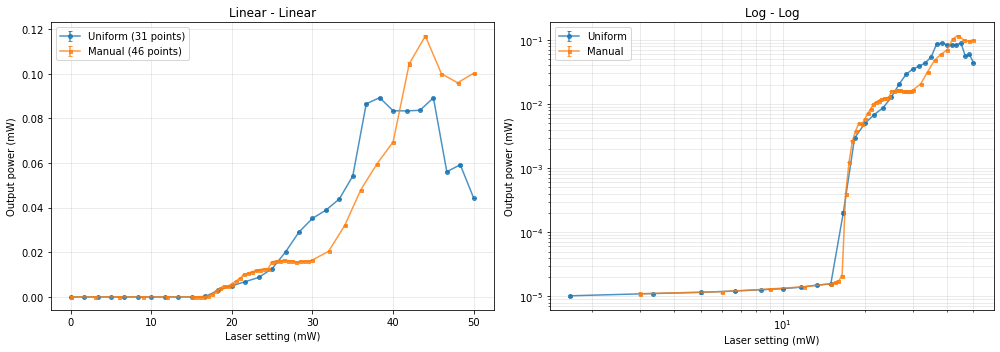

In [6]:

# Convert W to mW
up = uniform_p * 1000
uy = uniform_y * 1000
ue = uniform_err * 1000

mp = manual_p * 1000
my = manual_y * 1000
me = manual_err * 1000

mask_u = (up > 0) & (uy > 0)
mask_m = (mp > 0) & (my > 0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Linear - Linear
axes[0].errorbar(
    up, uy, yerr=ue,
    fmt='o-', capsize=2,
    markersize=4,
    label=f'Uniform ({len(up)} points)',
    alpha=0.8
)

axes[0].errorbar(
    mp, my, yerr=me,
    fmt='s-', capsize=2,
    markersize=3,
    label=f'Manual ({len(mp)} points)',
    alpha=0.8
)

axes[0].set_title("Linear - Linear")
axes[0].set_xlabel("Laser setting (mW)")
axes[0].set_ylabel("Output power (mW)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Log - Log
axes[1].errorbar(
    up[mask_u], uy[mask_u], yerr=ue[mask_u],
    fmt='o-', capsize=2,
    markersize=4,
    label="Uniform",
    alpha=0.8
)

axes[1].errorbar(
    mp[mask_m], my[mask_m], yerr=me[mask_m],
    fmt='s-', capsize=2,
    markersize=3,
    label="Manual",
    alpha=0.8
)

axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title("Log - Log")
axes[1].set_xlabel("Laser setting (mW)")
axes[1].set_ylabel("Output power (mW)")
axes[1].grid(True, which='both', alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

save comparison figure

In [7]:

figure_file = OUTPUT_DIR / (
        "comparison_" +
        datetime.now().strftime("%Y%m%d_%H%M%S") +
        ".png"
)

fig.savefig(
    figure_file,
    dpi=300,
    bbox_inches='tight'
)

print("Comparison figure saved:", figure_file)

print("\nMeasurement summary")
print("-----------------------")
print("Uniform points:", len(uniform_p))
print("Manual points:", len(manual_p))
print("Uniform output range (mW):",
      uniform_y.min() * 1000,
      uniform_y.max() * 1000)
print("Manual output range (mW):",
      manual_y.min() * 1000,
      manual_y.max() * 1000)


Comparison figure saved: D:\Data\2026\202610\20261019\comparison_20261019_164024.png

Measurement summary
-----------------------
Uniform points: 31
Manual points: 46
Uniform output range (mW): 9.251581675333334e-06 0.08927171164
Manual output range (mW): 8.691249932666667e-06 0.1169216496222222


GA setting

In [8]:
import csv
import numpy as np
import time
from datetime import datetime
from scipy.interpolate import PchipInterpolator

GA_MIN = 0.0
GA_MAX = 0.050
GA_TOTAL = 31
GA_INITIAL = np.linspace(GA_MIN, GA_MAX, 7)
GA_SETTLE = 1.0
GA_REPEATS = 3
GA_MIN_SPACING = 0.0001

assert 0 <= GA_MIN < GA_MAX <= MAX_ALLOWED
assert GA_TOTAL >= len(GA_INITIAL)

def ga_next_point(powers, outputs):
    p = np.asarray(powers, dtype=float)
    y = np.asarray(outputs, dtype=float)
    order = np.argsort(p)
    p, y = p[order], y[order]
    gaps = np.diff(p)
    mids = (p[:-1] + p[1:]) / 2
    valid = (gaps >= 2 * GA_MIN_SPACING)
    if not np.any(valid):
        return None
    if len(p) < 3:
        score = gaps / (GA_MAX - GA_MIN)
    else:
        smooth = PchipInterpolator(p, y)
        deviation = np.abs(smooth(mids) - (y[:-1] + y[1:]) / 2)
        scale = max(float(np.ptp(y)), 1e-12)
        score = deviation / scale + 0.05 * gaps / (GA_MAX - GA_MIN)
    score[~valid] = -np.inf
    return float(mids[int(np.argmax(score))])

print('GA ready; settings are in W. Initial points (mW):', GA_INITIAL * 1000)

GA ready; settings are in W. Initial points (mW): [ 0.          8.33333333 16.66666667 25.         33.33333333 41.66666667
 50.        ]


Execution

In [10]:


import csv
import time
import numpy as np
from datetime import datetime
from pathlib import Path
from scipy.interpolate import PchipInterpolator

# Configuration
GA_MIN = 0.000
GA_MAX = 0.050
GA_TOTAL = 31
GA_SETTLE = 1.0
GA_REPEATS = 3

MAX_ALLOWED = 0.060

# Initial points
GA_INITIAL = np.linspace(GA_MIN, GA_MAX, 7)

assert 0 <= GA_MIN < GA_MAX <= MAX_ALLOWED
assert GA_TOTAL >= len(GA_INITIAL)
assert GA_REPEATS >= 2

OUTPUT_DIR = Path("PhotonBEC_Data")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ga_p = []
ga_y = []
ga_err = []

ga_file = OUTPUT_DIR / (
        "greedy_" +
        datetime.now().strftime("%Y%m%d_%H%M%S") +
        ".csv"
)


def choose_next_point(p, y):
    """Select next pump setting using interpolation discrepancy."""

    p = np.asarray(p, dtype=float)
    y = np.asarray(y, dtype=float)

    order = np.argsort(p)
    p = p[order]
    y = y[order]

    midpoint = (p[:-1] + p[1:]) / 2
    width = np.diff(p)

    model = PchipInterpolator(p, y)

    predicted = model(midpoint)
    linear = (y[:-1] + y[1:]) / 2

    discrepancy = np.abs(predicted - linear)

    scale = max(np.ptp(y), 1e-12)

    score = discrepancy / scale + 0.05 * width / GA_MAX

    return float(midpoint[np.argmax(score)])


# One confirmation before starting
confirm = input(
    "Start automatic GA scan (0–50 mW)? Type YES: "
)

if confirm != "YES":
    raise RuntimeError("GA scan cancelled")

try:
    with open(ga_file, "w", newline="") as f:
        writer = csv.writer(f)

        writer.writerow([
            "Laser_setting_W",
            "Output_power_W",
            "Std_power_W",
            "Timestamp"
        ])

        for i in range(GA_TOTAL):

            # First 7 points: initial scan
            if i < len(GA_INITIAL):
                next_p = float(GA_INITIAL[i])

            # Remaining points: greedy selection
            else:
                next_p = choose_next_point(ga_p, ga_y)

            # Safety bound
            if not (GA_MIN <= next_p <= GA_MAX
                    and next_p <= MAX_ALLOWED):
                raise ValueError(
                    "GA requested setting outside allowed range"
                )

            # Set laser
            laser.set(next_p)
            time.sleep(GA_SETTLE)

            # Measure Power Meter A
            readings = np.array([
                powermeter.take_power_reading()
                for _ in range(GA_REPEATS)
            ], dtype=float)

            if not np.all(np.isfinite(readings)):
                raise ValueError("Invalid power meter reading")

            mean = float(np.mean(readings))
            std = float(np.std(readings, ddof=1))

            ga_p.append(next_p)
            ga_y.append(mean)
            ga_err.append(std)

            # Save each point immediately
            writer.writerow([
                next_p,
                mean,
                std,
                datetime.now().isoformat()
            ])
            f.flush()

            print(
                f"[{i + 1:02d}/{GA_TOTAL}] "
                f"Pump: {next_p * 1000:.3f} mW | "
                f"Output: {mean * 1000:.6f} mW"
            )

except KeyboardInterrupt:
    print("GA scan interrupted by user.")

finally:
    print("Measurement loop ended.")
    print("Check laser state using laboratory procedure.")
    print("Data file:", ga_file)

ga_p = np.asarray(ga_p)
ga_y = np.asarray(ga_y)
ga_err = np.asarray(ga_err)

print("Completed points:", len(ga_p))


[01/31] Pump: 0.000 mW | Output: 0.000009 mW
[02/31] Pump: 8.333 mW | Output: 0.000013 mW
[03/31] Pump: 16.667 mW | Output: 0.000018 mW
[04/31] Pump: 25.000 mW | Output: 0.020057 mW
[05/31] Pump: 33.333 mW | Output: 0.031644 mW
[06/31] Pump: 41.667 mW | Output: 0.047189 mW
[07/31] Pump: 50.000 mW | Output: 0.135445 mW
[08/31] Pump: 45.833 mW | Output: 0.088138 mW
[09/31] Pump: 43.750 mW | Output: 0.078824 mW
[10/31] Pump: 47.917 mW | Output: 0.108016 mW
[11/31] Pump: 37.500 mW | Output: 0.026942 mW
[12/31] Pump: 39.583 mW | Output: 0.043447 mW
[13/31] Pump: 29.167 mW | Output: 0.023865 mW
[14/31] Pump: 20.833 mW | Output: 0.011583 mW
[15/31] Pump: 18.750 mW | Output: 0.000027 mW
[16/31] Pump: 46.875 mW | Output: 0.094241 mW
[17/31] Pump: 22.917 mW | Output: 0.014710 mW
[18/31] Pump: 42.708 mW | Output: 0.075257 mW
[19/31] Pump: 31.250 mW | Output: 0.027646 mW
[20/31] Pump: 12.500 mW | Output: 0.000015 mW
[21/31] Pump: 4.167 mW | Output: 0.000011 mW
[22/31] Pump: 38.542 mW | Output: 0.0

Compare GA to uniform and manual

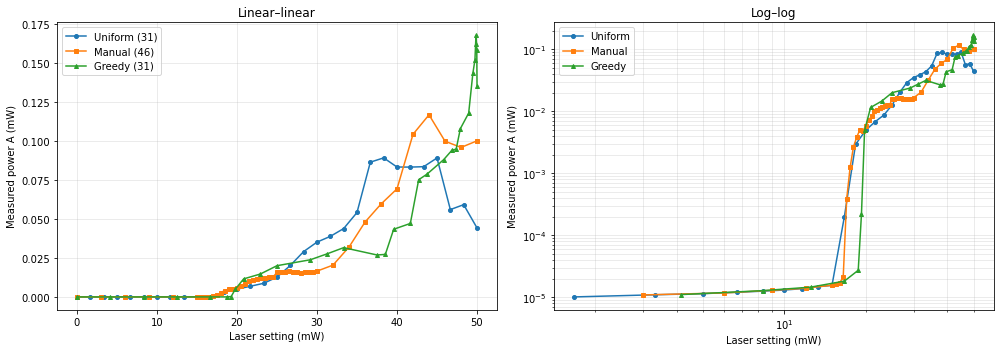

In [11]:
fig_ga, axes_ga = plt.subplots(1, 2, figsize=(14, 5))
for prefix, name, marker in [('uniform', 'Uniform', 'o'), ('manual', 'Manual', 's'), ('ga', 'Greedy', '^')]:
    if not all(k in globals() for k in (prefix+'_p', prefix+'_y')):
        continue
    x = np.asarray(globals()[prefix+'_p']) * 1000
    y = np.asarray(globals()[prefix+'_y']) * 1000
    ix = np.argsort(x)
    x, y = x[ix], y[ix]
    axes_ga[0].plot(x, y, marker+'-', ms=4, label=f'{name} ({len(x)})')
    mask = (x > 0) & (y > 0)
    axes_ga[1].plot(x[mask], y[mask], marker+'-', ms=4, label=name)
for ax in axes_ga:
    ax.set_xlabel('Laser setting (mW)')
    ax.set_ylabel('Measured power A (mW)')
    ax.grid(True, which='both', alpha=0.3)
    ax.legend()
axes_ga[0].set_title('Linear–linear')
axes_ga[1].set_title('Log–log')
axes_ga[1].set_xscale('log')
axes_ga[1].set_yscale('log')
plt.tight_layout()
plt.show()